<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_5/tugas_praktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tugas Praktikum**

1. Pilih salah satu dataset nyata dari sklearn.datasets (misalnya iris dataset atau digits dataset).

2. Lakukan clustering dengan HDBSCAN.

3. Laporkan hasil:
    - Jumlah cluster yang terbentuk.
    - Banyaknya noise.
    - Visualisasi (gunakan PCA/TSNE untuk reduksi dimensi jika perlu).

4. Buat analisis singkat: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

In [ ]:
df = pd.read_csv('Iris.csv')
X = df.drop(['Id', 'Species'], axis=1, errors='ignore')
y_true = df['Species']

In [ ]:
# Clustering dengan HDBSCAN
clusterer = HDBSCAN(min_cluster_size=10, min_samples=5)
labels = clusterer.fit_predict(X)

In [ ]:
# Hitung metrik
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)
ari = adjusted_rand_score(y_true, labels)

print(f"Jumlah cluster: {n_clusters}")
print(f"Banyaknya noise: {n_noise}")
print(f"Adjusted Rand Index (ARI): {ari:.3f}")

Jumlah cluster: 2
Banyaknya noise: 0
Adjusted Rand Index (ARI): 0.568


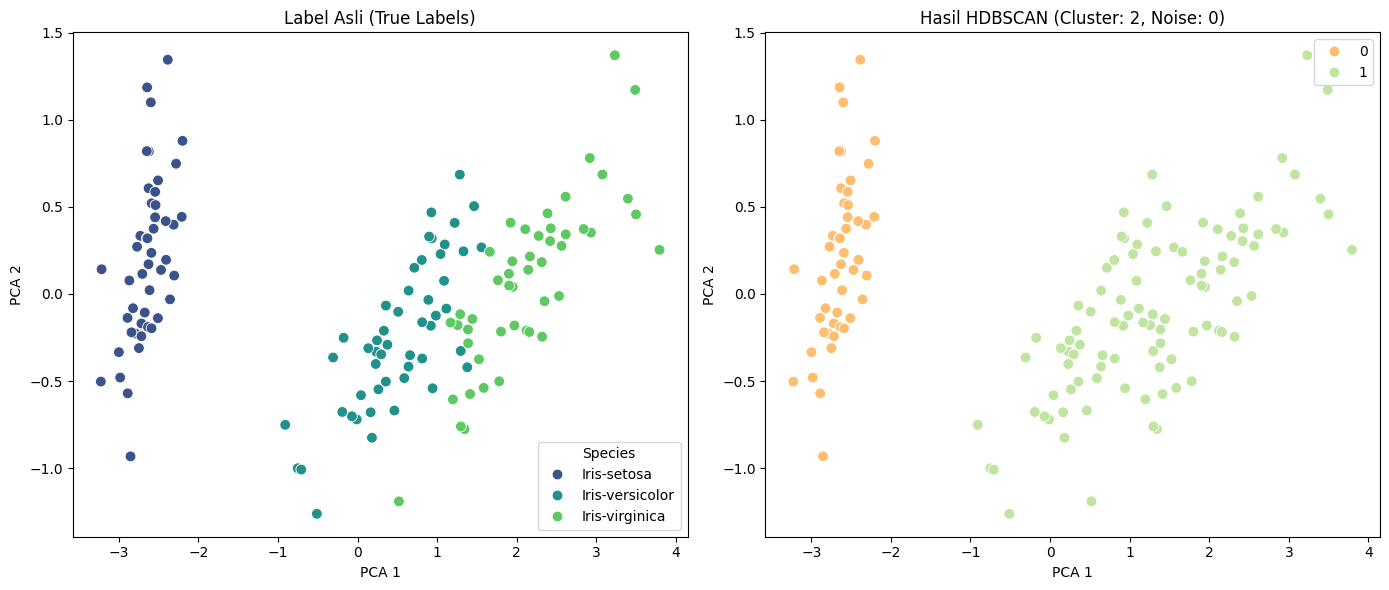

In [2]:
# Visualisasi Reduksi Dimensi dengan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot Label Asli
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_true, palette='viridis', ax=axes[0], s=60)
axes[0].set_title("Label Asli (True Labels)")
axes[0].set_xlabel("PCA 1")
axes[0].set_ylabel("PCA 2")

# Plot Hasil HDBSCAN
unique_labels = sorted(list(set(labels)))
palette = sns.color_palette("Spectral", len(unique_labels))
if -1 in unique_labels:
    palette[unique_labels.index(-1)] = (0.0, 0.0, 0.0)

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette=palette, ax=axes[1], s=60)
axes[1].set_title(f"Hasil HDBSCAN (Cluster: {n_clusters}, Noise: {n_noise})")
axes[1].set_xlabel("PCA 1")
axes[1].set_ylabel("PCA 2")

plt.tight_layout()
plt.show()

## **ANALISIS SINGKAT**

Hasil Clustering HDBSCAN tidak sepenuhnya sesuai dengan label asli dataset Iris.
  - Perbedaan Jumlah Kelompok. Dataset asli memiliki 3 label kelas yaitu Setosa, Versicolor, dan Virginica. Namun, algoritma HDBSCAN hanya berhasil membentuk 2 cluster.
  - Pemisahan Kelas Setosa. Spesies Setosa memiliki karakteristik data yang terpisah secara jelas dari spesies lainnya. Hal ini membuat HDBSCAN berhasil mengenali dan mengelompokkannya sebagai satu cluster tersendiri.
  - Tumpang Tindih Versicolor dan Virginica. Spesies Versicolor dan Virginica memiliki ukuran fitur yang sangat mirip dan saling tumpang tindih. Karena HDBSCAN mengelompokkan data berdasarkan kepadatan, algoritma ini mendeteksi area tumpang tindih tersebut sebagai satu kesatuan area yang padat dan menggabungkan kedua spesies ini ke dalam satu cluster yang sama.
  - Skor Evaluasi. Nilai Adjusted Rand Index (ARI) yang dihasilkan adalah 0.568. Angka ini berada di tingkat menengah yang membuktikan bahwa hasil pengelompokan HDBSCAN tidak memiliki tingkat kecocokan yang sempurna dengan label aslinya. Tingkat kecocokan sempurna ditunjukkan dengan nilai